# Gêmeo digital térmico — dissipador de GPU

**Autor:** Nicolas Melo · CEUB · Fundamentos de Engenharia.

Geometria autoral180×90×29mm,20aletas, alumínio6063-T6 e cobreC11000. Fonte equivalente170W; **não representa medição nem validação de uma RTX3060**. A ficha MSI informa170W da placa inteira. O limite85°C é uma meta adotada.

**Execução:** os resultados gravados foram produzidos localmente em Python3.12. O notebook é autocontido e compatível com Google Colab; abrir no Colab não comprova execução no runtime Google. Para essa evidência, entre na sua conta e use Ambiente de execução → Executar tudo.

**Declaração de IA:** elaboração assistida por inteligência artificial para organizar texto, programar e conferir cálculos; o autor deve revisar e compreender os resultados antes da entrega.

## 1. Dependências
Instala somente bibliotecas ausentes. No Colab, CoolProp pode precisar de instalação. Não exige Drive, repositório ou arquivos externos. A reprodução local de referência usa requirements.txt com versões fixadas.

In [1]:
import importlib.util, subprocess, sys
packages = {'numpy':'numpy', 'scipy':'scipy', 'matplotlib':'matplotlib', 'CoolProp':'CoolProp'}
missing = [distribution for module, distribution in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Python:', sys.version.split()[0])

Python: 3.12.13


## 2. Parâmetros e hipóteses
Valores SI no cálculo; dimensões do CAD em mm convertidas explicitamente. h80W/(m²K), resistência interna0,1K/W, contato e capacidade da fonte são **hipóteses não calibradas**. Fundo da base adiabático; convecção prescrita no topo livre, bordas e aletas. Sem radiação, heat pipes, memória/VRM ou CFD. Furos do CAD omitidos na malha. Aletas com eficiência analítica; massa integral concentrada na base local no transiente, uma aproximação de armazenamento. Cobre isotérmico, sem resolver espalhamento interno em3D.

In [2]:
import json
parameters = json.loads('{\n  "study": {"title": "Gemeo digital termico de um dissipador para GPU", "author": "Nicolas Melo", "institution": "Centro Universitario de Brasilia (CEUB)", "course": "Fundamentos de Engenharia", "date": "2026-10-18", "reference_gpu": "MSI GeForce RTX 3060 VENTUS 2X 12G OC", "reference_board_power_W": 170.0, "reference_board_envelope_mm": [235, 124, 42], "disclaimer": "Geometria autoral didatica; 170 W da placa inteira concentrados em uma fonte equivalente. Nao e uma replica nem validacao da GPU comercial."},\n  "geometry_mm": {"base_length": 180.0, "base_width": 90.0, "base_thickness": 6.0, "fin_count": 20, "fin_thickness": 1.0, "fin_height": 20.0, "fin_pitch": 3.5, "copper_length": 40.0, "copper_width": 40.0, "copper_thickness": 3.0, "source_length": 30.0, "source_width": 30.0, "tim_thickness": 0.1, "mounting_hole_diameter": 3.2, "mounting_hole_centres": [[10.0, 5.0], [170.0, 5.0], [10.0, 85.0], [170.0, 85.0]]},\n  "materials": {"aluminium": {"designation": "Aluminium 6063-T6", "k_W_mK": 201.0, "rho_kg_m3": 2700.0, "cp_J_kgK": 900.0, "E_Pa": 69000000000.0, "alpha_per_K": 0.0000234, "yield_Pa": 170000000.0, "notes": "Hydro: k, expansao, densidade e escoamento; E e cp sao valores tipicos aproximados a temperatura ambiente, nao certificacao do lote."}, "copper": {"designation": "Copper C11000 (ETP)", "k_W_mK": 391.0, "rho_kg_m3": 8910.0, "cp_J_kgK": 385.0, "E_Pa": 117000000000.0, "alpha_per_K": 0.00001692, "notes": "Valores arredondados e convertidos da ficha CDA C11000 a temperatura ambiente."}, "tim": {"designation": "Pasta termica ceramica generica", "k_W_mK": 3.0, "notes": "Hipotese didatica; requer ficha tecnica e medicao na aplicacao real."}},\n  "thermal": {"power_W": 170.0, "ambient_C": 25.0, "initial_C": 25.0, "design_limit_C": 85.0, "h_W_m2K": 80.0, "source_package_R_K_W": 0.1, "source_package_C_J_K": 3.5, "source_contact_R_K_W": 0.02, "copper_aluminium_contact_r_m2K_W": 0.00002, "duration_s": 600.0, "step_s": 0.5, "export_interval_s": 2.0, "grid_mm": [3.0, 1.5, 0.75], "sensitivity_h_W_m2K": [20.0, 40.0, 60.0, 80.0, 100.0], "sensitivity_power_W": [100.0, 140.0, 170.0, 200.0], "sensitivity_ambient_C": [25.0, 35.0], "notes": "h, resistencia interna do encapsulamento, capacitancia equivalente e contatos sao hipoteses nao calibradas. Limite de 85 C e meta de projeto, nao limite oficial do fabricante. Sem heat pipes, CFD ou simulacao de memoria/VRM. O solver espacial representa a base em 2D com aletas por eficiencia analitica; furos podem ser desprezados no solver com erro geometrico explicitado."},\n  "environmental": {"hours_per_year": 8760.0, "grid_factor_kgCO2e_kWh": 0.1, "grid_factor_sensitivity_kgCO2e_kWh": [0.05, 0.1, 0.5], "alternative_power_W": 140.0, "years": 5, "aluminium_price_R_per_kg": 30.0, "copper_price_R_per_kg": 100.0, "notes": "Fatores de emissao e precos sao cenarios ilustrativos, nao cotacao nem inventario oficial brasileiro. Consumo da placa somente; 170 W ja e valor da placa, sem somar ventoinhas novamente. Impactos incorporados discutidos qualitativamente, sem alegar ACV completa."},\n  "sources": {"gpu": "https://storage-asset.msi.com/datasheet/vga/global/GeForce-RTX-3060-VENTUS-2X-12G-OC.pdf", "aluminium": "https://www.hydro.com/globalassets/01-products--services/extruded-profiles/americas/ena-resources/alloy-data-sheets/hydro_2026_data_sheet_6063-rev-062026.pdf", "copper": "https://alloys.copper.org/alloy/C11000", "energy2d": "https://energy.concord.org/energy2d/", "freecad": "https://www.freecad.org/", "colab": "https://colab.research.google.com/"}\n}\n')
print(json.dumps(parameters['thermal'], ensure_ascii=False, indent=2))

{
  "power_W": 170.0,
  "ambient_C": 25.0,
  "initial_C": 25.0,
  "design_limit_C": 85.0,
  "h_W_m2K": 80.0,
  "source_package_R_K_W": 0.1,
  "source_package_C_J_K": 3.5,
  "source_contact_R_K_W": 0.02,
  "copper_aluminium_contact_r_m2K_W": 2e-05,
  "duration_s": 600.0,
  "step_s": 0.5,
  "export_interval_s": 2.0,
  "grid_mm": [
    3.0,
    1.5,
    0.75
  ],
  "sensitivity_h_W_m2K": [
    20.0,
    40.0,
    60.0,
    80.0,
    100.0
  ],
  "sensitivity_power_W": [
    100.0,
    140.0,
    170.0,
    200.0
  ],
  "sensitivity_ambient_C": [
    25.0,
    35.0
  ],
  "notes": "h, resistencia interna do encapsulamento, capacitancia equivalente e contatos sao hipoteses nao calibradas. Limite de 85 C e meta de projeto, nao limite oficial do fabricante. Sem heat pipes, CFD ou simulacao de memoria/VRM. O solver espacial representa a base em 2D com aletas por eficiencia analitica; furos podem ser desprezados no solver com erro geometrico explicitado."
}


## 3. Método
Balanço conservativo por volumes finitos no plano da base. Cada ligação conduz G(Ti−Tj); cada fronteira perde hAef(T−T∞). Para cada aleta, η=tanh(mLc)/(mLc), m²≈2h/(kt), Lc=H+t/2. Área de contato de cobre obtida por sobreposição exata de células. Kθ=b no equilíbrio; (C/Δt+K)θⁿ⁺¹=b+Cθⁿ/Δt no transiente.

A média exportada do alumínio inclui perfil analítico nas aletas; o mapa espacial representa somente a base. Estabilidade do método implícito não equivale a precisão; comparam-se malhas e passos.

In [3]:
"""2-D finite-volume base conduction + analytical fins + lumped copper/package.

Temperatures are scenario predictions, not measured/validated RTX3060 temperatures.
The underside is adiabatic except for copper input. Uniform prescribed h applies
on uncovered top, base perimeter and fin sides/tips; fin end faces are omitted.
Fins have quasi-steady efficiency but their full mass is lumped at local base
nodes for transient storage. Copper is isothermal. Holes are omitted in the
thermal grid (their exact volume is reported separately). No CFD or heat pipes.
"""
from __future__ import annotations

import copy
import csv
import json
from dataclasses import dataclass
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import coo_matrix, diags
from scipy.sparse.linalg import spsolve, factorized
from CoolProp.CoolProp import PropsSI


@dataclass
class Model:
    K: object
    capacity: np.ndarray
    convection: np.ndarray
    aluminium_mean_weights: np.ndarray
    x: np.ndarray
    y: np.ndarray
    nx: int
    ny: int
    copper: int
    source: int
    metadata: dict


def overlap(edges, low, high):
    return np.maximum(0.0, np.minimum(edges[1:], high) - np.maximum(edges[:-1], low))


def assemble(p, grid_mm=1.5, h=None):
    g, t = p["geometry_mm"], p["thermal"]
    al, cu = p["materials"]["aluminium"], p["materials"]["copper"]
    h = t["h_W_m2K"] if h is None else h
    L, W, b, H, f, pitch = [g[key] * 1e-3 for key in ["base_length", "base_width", "base_thickness", "fin_height", "fin_thickness", "fin_pitch"]]
    nx, ny = int(round(L / (grid_mm * 1e-3))), int(round(W / (grid_mm * 1e-3)))
    xe, ye = np.linspace(0, L, nx + 1), np.linspace(0, W, ny + 1)
    dx, dy = L / nx, W / ny
    n = nx * ny
    ids = np.arange(n).reshape(ny, nx)
    rows, cols, vals = [], [], []
    diagonal = np.zeros(n + 2)

    def connect(a, b_ids, conductance):
        a, b_ids = np.atleast_1d(a).astype(int), np.atleast_1d(b_ids).astype(int)
        c = np.broadcast_to(conductance, a.shape)
        rows.extend(np.concatenate([a, b_ids]).tolist())
        cols.extend(np.concatenate([b_ids, a]).tolist())
        vals.extend(np.concatenate([-c, -c]).tolist())
        np.add.at(diagonal, a, c)
        np.add.at(diagonal, b_ids, c)

    connect(ids[:, :-1].ravel(), ids[:, 1:].ravel(), al["k_W_mK"] * b * dy / dx)
    connect(ids[:-1, :].ravel(), ids[1:, :].ravel(), al["k_W_mK"] * b * dx / dy)
    root_width_by_row = np.zeros(ny)
    margin = (W - ((g["fin_count"] - 1) * pitch + f)) / 2
    for i in range(g["fin_count"]):
        root_width_by_row += overlap(ye, margin + i * pitch, margin + i * pitch + f)
    root_area = np.repeat((root_width_by_row * dx)[:, None], nx, axis=1).ravel()
    m = np.sqrt(2 * h / (al["k_W_mK"] * f))
    lc = H + f / 2
    efficiency = float(np.tanh(m * lc) / (m * lc))
    fin_area_by_cell = root_area / f * (2 * H + f)
    bare_area = dx * dy - root_area
    conv = np.zeros(n + 2)
    conv[:n] = h * (bare_area + efficiency * fin_area_by_cell)
    conv[ids[:, 0]] += h * b * dy
    conv[ids[:, -1]] += h * b * dy
    conv[ids[0, :]] += h * b * dx
    conv[ids[-1, :]] += h * b * dx
    diagonal += conv
    copper_L, copper_W, copper_b = [g[key] * 1e-3 for key in ["copper_length", "copper_width", "copper_thickness"]]
    ox = overlap(xe, (L - copper_L) / 2, (L + copper_L) / 2)
    oy = overlap(ye, (W - copper_W) / 2, (W + copper_W) / 2)
    copper_overlap = np.outer(oy, ox).ravel()
    area_resistance = copper_b / (2 * cu["k_W_mK"]) + b / (2 * al["k_W_mK"]) + t["copper_aluminium_contact_r_m2K_W"]
    contact_ids = np.flatnonzero(copper_overlap > 0)
    connect(contact_ids, np.full(contact_ids.size, n), copper_overlap[contact_ids] / area_resistance)
    source_area = g["source_length"] * g["source_width"] * 1e-6
    tim_R = g["tim_thickness"] * 1e-3 / (p["materials"]["tim"]["k_W_mK"] * source_area)
    source_R = t["source_package_R_K_W"] + t["source_contact_R_K_W"] + tim_R + copper_b / (2 * cu["k_W_mK"] * source_area)
    connect(np.array([n]), np.array([n + 1]), 1 / source_R)
    rows.extend(range(n + 2)); cols.extend(range(n + 2)); vals.extend(diagonal.tolist())
    K = coo_matrix((vals, (rows, cols)), shape=(n + 2, n + 2)).tocsc()
    capacity = np.zeros(n + 2)
    capacity[:n] = al["rho_kg_m3"] * al["cp_J_kgK"] * (dx * dy * b + root_area * H)
    capacity[n] = copper_L * copper_W * copper_b * cu["rho_kg_m3"] * cu["cp_J_kgK"]
    capacity[n + 1] = t["source_package_C_J_K"]
    aluminium_mean_weights = (dx * dy * b + efficiency * root_area * H) / (L * W * b + root_area.sum() * H)
    holes_m3 = len(g["mounting_hole_centres"]) * np.pi * (g["mounting_hole_diameter"] * 0.0005) ** 2 * b
    meta = {"grid_mm": grid_mm, "grid_shape": [ny, nx], "unknowns": n + 2,
            "h_W_m2K": h, "fin_efficiency": efficiency,
            "fin_area_m2": float(fin_area_by_cell.sum()), "bare_area_m2": float(bare_area.sum() + 2 * (L + W) * b),
            "effective_area_m2": float(conv.sum() / h), "global_convection_W_K": float(conv.sum()),
            "source_to_copper_R_K_W": source_R, "tim_R_K_W": tim_R,
            "copper_to_base_area_resistance_m2K_W": area_resistance,
            "aluminium_mass_without_holes_kg": float(capacity[:n].sum() / al["cp_J_kgK"]),
            "copper_mass_kg": float(capacity[n] / cu["cp_J_kgK"]),
            "omitted_hole_volume_m3": float(holes_m3),
            "fin_transverse_Biot": h * f / (2 * al["k_W_mK"]),
            "copper_contact_area_m2": float(copper_overlap.sum())}
    return Model(K, capacity, conv, aluminium_mean_weights, (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2, nx, ny, n, n + 1, meta)


def equilibrium(model, power_W, ambient_C):
    load = np.zeros(model.source + 1)
    load[model.source] = power_W
    theta = spsolve(model.K, load)
    heat_out = float(model.convection @ theta)
    temperature = theta + ambient_C
    return temperature, {"source_C": float(temperature[model.source]), "copper_C": float(temperature[model.copper]),
                         "base_max_C": float(temperature[:model.copper].max()),
                         "base_min_C": float(temperature[:model.copper].min()),
                         "base_mean_C": float(temperature[:model.copper].mean()),
                         "aluminium_volume_mean_C": float(ambient_C + model.aluminium_mean_weights @ theta[:model.copper]),
                         "heat_out_W": heat_out, "energy_residual_W": float(power_W - heat_out),
                         "effective_source_to_ambient_R_K_W": float(theta[model.source] / power_W) if power_W else None}


def transient(model, p, dt=None):
    t = p["thermal"]
    dt = t["step_s"] if dt is None else dt
    steps = int(round(t["duration_s"] / dt))
    export_every = int(round(t["export_interval_s"] / dt))
    theta = np.full(model.source + 1, t["initial_C"] - t["ambient_C"])
    load = np.zeros_like(theta); load[model.source] = t["power_W"]
    solve = factorized(model.K + diags(model.capacity / dt, format="csc"))
    samples = []
    residual_max = 0.0
    def sample(time):
        return [time, theta[model.source] + t["ambient_C"], theta[model.copper] + t["ambient_C"],
                theta[:model.copper].mean() + t["ambient_C"], theta[:model.copper].max() + t["ambient_C"],
                model.aluminium_mean_weights @ theta[:model.copper] + t["ambient_C"]]
    samples.append(sample(0.0))
    cumulative_out_J = 0.0
    initial_energy_J = float(model.capacity @ theta)
    for step in range(1, steps + 1):
        before = theta
        theta = solve(load + model.capacity / dt * before)
        out = float(model.convection @ theta)
        cumulative_out_J += dt * out
        residual = float(model.capacity @ ((theta - before) / dt) - (t["power_W"] - out))
        residual_max = max(residual_max, abs(residual))
        if step % export_every == 0 or step == steps:
            samples.append(sample(step * dt))
    stored_J = float(model.capacity @ theta) - initial_energy_J
    return np.array(samples), {"dt_s": dt, "grid_mm": model.metadata["grid_mm"], "duration_s": steps * dt,
                               "max_step_energy_residual_W": residual_max,
                               "cumulative_energy_residual_J": t["power_W"] * steps * dt - cumulative_out_J - stored_J,
                               "stored_energy_J": stored_J, "rejected_energy_J": cumulative_out_J,
                               "final_source_C": float(theta[model.source] + t["ambient_C"])}


def write_csv(path, rows, fields=None):
    with path.open("w", newline="", encoding="utf-8") as stream:
        if fields is None:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
        else:
            writer = csv.writer(stream); writer.writerow(fields); writer.writerows(rows)


def run_study(p, output_root):
    root = Path(output_root)
    results, figures = root / "results", root / "figures"
    results.mkdir(parents=True, exist_ok=True); figures.mkdir(parents=True, exist_ok=True)
    t = p["thermal"]
    mesh = []
    for grid in t["grid_mm"]:
        model = assemble(p, grid)
        _, eq = equilibrium(model, t["power_W"], t["ambient_C"])
        mesh.append({"grid_mm": grid, "unknowns": model.metadata["unknowns"], **eq})
    model = assemble(p, 1.5)
    temperature, eq = equilibrium(model, t["power_W"], t["ambient_C"])
    samples, transient_info = transient(model, p)
    timestep = []
    for dt in [1.0, 0.5, 0.25]:
        data, info = (samples, transient_info) if dt == t["step_s"] else transient(model, p, dt)
        timestep.append({"dt_s": dt, "source_at_10s_C": float(data[np.argmin(abs(data[:, 0] - 10)), 1]), "source_at_60s_C": float(data[np.argmin(abs(data[:, 0] - 60)), 1]), "final_source_C": info["final_source_C"]})
    scenarios = []
    for h in t["sensitivity_h_W_m2K"]:
        h_model = model if h == t["h_W_m2K"] else assemble(p, 1.5, h)
        unit_temperature, _ = equilibrium(h_model, 1.0, 0.0)
        for power in t["sensitivity_power_W"]:
            for ambient in t["sensitivity_ambient_C"]:
                source = float(ambient + power * unit_temperature[h_model.source])
                scenarios.append({"h_W_m2K": h, "power_W": power, "ambient_C": ambient, "source_C": source,
                                  "base_max_C": float(ambient + power * unit_temperature[:h_model.copper].max()),
                                  "meets_adopted_85C_goal": source <= t["design_limit_C"]})
    air = {key: float(PropsSI(code, "T", t["ambient_C"] + 273.15, "P", 101325, "Air"))
           for key, code in [("density_kg_m3", "D"), ("viscosity_Pa_s", "V"), ("k_W_mK", "L"), ("cp_J_kgK", "C")]}
    air["assumed_context_velocity_m_s"] = 2.0
    air["Re_over_180mm_at_assumed_2m_s"] = air["density_kg_m3"] * 2.0 * p["geometry_mm"]["base_length"] * 1e-3 / air["viscosity_Pa_s"]
    summary = {"method": __doc__, "parameters": p, "model": model.metadata, "equilibrium": eq,
               "transient": transient_info, "mesh_convergence": mesh, "timestep_convergence": timestep, "air_CoolProp": air,
               "mesh_selected_vs_finest_source_difference_K": abs(eq["source_C"] - mesh[-1]["source_C"]),
               "end_vs_steady_source_difference_K": abs(eq["source_C"] - transient_info["final_source_C"]),
               "meets_adopted_85C_goal": eq["source_C"] <= t["design_limit_C"],
               "provenance": "Python execution; no commercial GPU validation. Colab-compatible notebook executed locally, not authenticated Google runtime."}
    (results / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    write_csv(results / "scenarios.csv", scenarios)
    write_csv(results / "grid_convergence.csv", mesh)
    write_csv(results / "timestep_convergence.csv", timestep)
    write_csv(results / "transient.csv", samples, ["time_s", "source_C", "copper_C", "base_mean_C", "base_max_C", "aluminium_volume_mean_C"])
    playback = {"version": 1, "source": "Original didactic180x90x29mm heatsink, Al6063-T6/CuC11000; 2D FVM+analytical fins, equivalent170W source, h80W/m2K assumed,25C ambient. Not MSI RTX3060 validation. gpu=equivalent package, base=mean copper, heatsink=volume-mean aluminium including analytical fin profiles. Visual GPU geometry is different from this study.",
                "timesSeconds": samples[:, 0].tolist(), "temperaturesC": {"gpu": samples[:, 1].tolist(), "base": samples[:, 2].tolist(), "heatsink": samples[:, 5].tolist()}}
    (results / "gpu-twin-results.json").write_text(json.dumps(playback, ensure_ascii=False) + "\n", encoding="utf-8")
    plt.rcParams.update({"font.size": 10, "figure.dpi": 150, "axes.grid": False})
    fig, ax = plt.subplots(figsize=(9, 4.8))
    im = ax.imshow(temperature[:model.copper].reshape(model.ny, model.nx), origin="lower", extent=[0, 180, 0, 90], cmap="inferno", aspect="equal")
    from matplotlib.patches import Rectangle
    ax.add_patch(Rectangle((70, 25), 40, 40, fill=False, edgecolor="cyan", linewidth=1.2, label="Contato do cobre40x40mm"))
    ax.set(xlabel="Comprimento da base (mm)", ylabel="Largura da base (mm)", title="Temperatura da base de alumínio — equilíbrio do cenário")
    fig.colorbar(im, ax=ax, label="Temperatura (°C)"); ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout(); fig.savefig(figures / "temperature_map.png"); plt.close(fig)
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for column, label in [(1, "Fonte equivalente"), (2, "Base de cobre"), (3, "Média da base de alumínio")]:
        ax.plot(samples[:, 0], samples[:, column], label=label)
    ax.axhline(t["design_limit_C"], color="red", linestyle="--", label="Meta adotada85°C")
    ax.set(xlabel="Tempo (s)", ylabel="Temperatura (°C)", title="Aquecimento sob carga constante170W")
    ax.legend(fontsize=8); ax.grid(alpha=0.25); fig.tight_layout(); fig.savefig(figures / "transient.png"); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
    for ax, ambient in zip(axes, [25.0, 35.0]):
        for power in t["sensitivity_power_W"]:
            selected = [s for s in scenarios if s["power_W"] == power and s["ambient_C"] == ambient]
            ax.plot([s["h_W_m2K"] for s in selected], [s["source_C"] for s in selected], "o-", label=f"{power:g}W")
        ax.axhline(t["design_limit_C"], color="red", linestyle="--")
        ax.set(xlabel="h prescrito (W/m²K)", title=f"Ambiente{ambient:g}°C"); ax.grid(alpha=0.25)
    axes[0].set_ylabel("Temperatura da fonte equivalente (°C)"); axes[1].legend(fontsize=8)
    fig.suptitle("Sensibilidade — h não é uma vazão calculada"); fig.tight_layout(); fig.savefig(figures / "sensitivity.png"); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 4.3))
    ax.plot([r["grid_mm"] for r in mesh], [r["source_C"] for r in mesh], "o-")
    ax.invert_xaxis(); ax.set(xlabel="Tamanho da célula (mm)", ylabel="Temperatura da fonte (°C)", title="Convergência espacial do modelo reduzido"); ax.grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(figures / "grid_convergence.png"); plt.close(fig)
    if abs(eq["energy_residual_W"]) > 1e-6 or transient_info["max_step_energy_residual_W"] > 1e-5:
        raise RuntimeError("Energy balance did not close within numerical tolerance")
    return summary



## 4. Executar estudo e verificar balanço
Executa3malhas,3passos de tempo,40cenários e consulta propriedades do ar com CoolProp. A velocidade2m/s é somente contexto para Reynolds; **não calcula nem valida h80**.

In [4]:
output_root = Path('gpu_thermal_outputs')
summary = run_study(parameters, output_root)
for key in ['equilibrium','transient','mesh_selected_vs_finest_source_difference_K','meets_adopted_85C_goal','air_CoolProp']:
    print(key, json.dumps(summary[key], ensure_ascii=False, indent=2))

equilibrium {
  "source_C": 83.68108221123153,
  "copper_C": 56.26014823377582,
  "base_max_C": 54.27231532688391,
  "base_min_C": 31.903632372177675,
  "base_mean_C": 39.05449798510305,
  "aluminium_volume_mean_C": 38.59056849421773,
  "heat_out_W": 169.99999999997453,
  "energy_residual_W": 2.546585164964199e-11,
  "effective_source_to_ambient_R_K_W": 0.34518283653665605
}
transient {
  "dt_s": 0.5,
  "grid_mm": 1.5,
  "duration_s": 600.0,
  "max_step_energy_residual_W": 5.589107299940272e-11,
  "cumulative_energy_residual_J": 2.848173608072102e-08,
  "stored_energy_J": 6555.407849898209,
  "rejected_energy_J": 95444.59215007331,
  "final_source_C": 83.68108091282312
}
mesh_selected_vs_finest_source_difference_K 0.021645751667378477
meets_adopted_85C_goal true
air_CoolProp {
  "density_kg_m3": 1.1843184839089664,
  "viscosity_Pa_s": 1.8448082162002025e-05,
  "k_W_mK": 0.026246931318905948,
  "cp_J_kgK": 1006.308142514125,
  "assumed_context_velocity_m_s": 2.0,
  "Re_over_180mm_at_ass

## 5. Resultados gráficos
Distribuição espacial, evolução temporal e sensibilidade às hipóteses. Uma pequena margem abaixo85°C não é garantia de segurança diante de h/contatos não medidos.

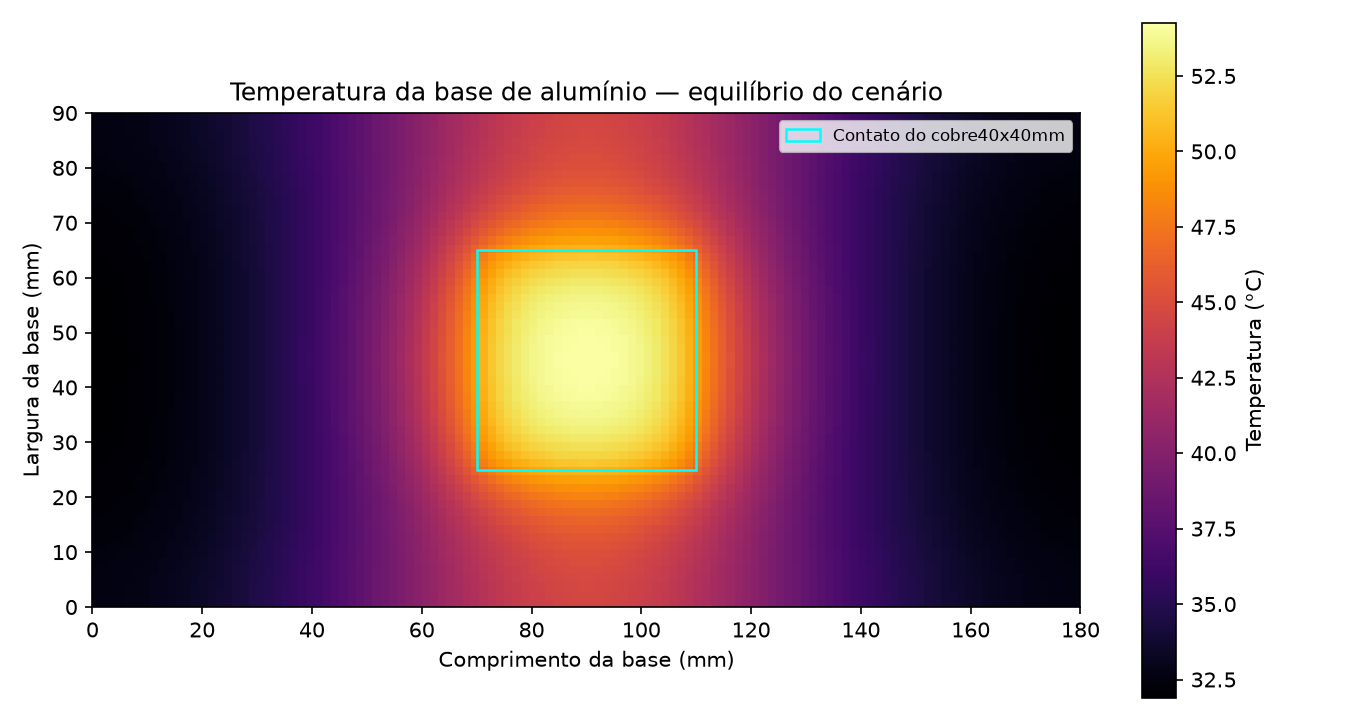

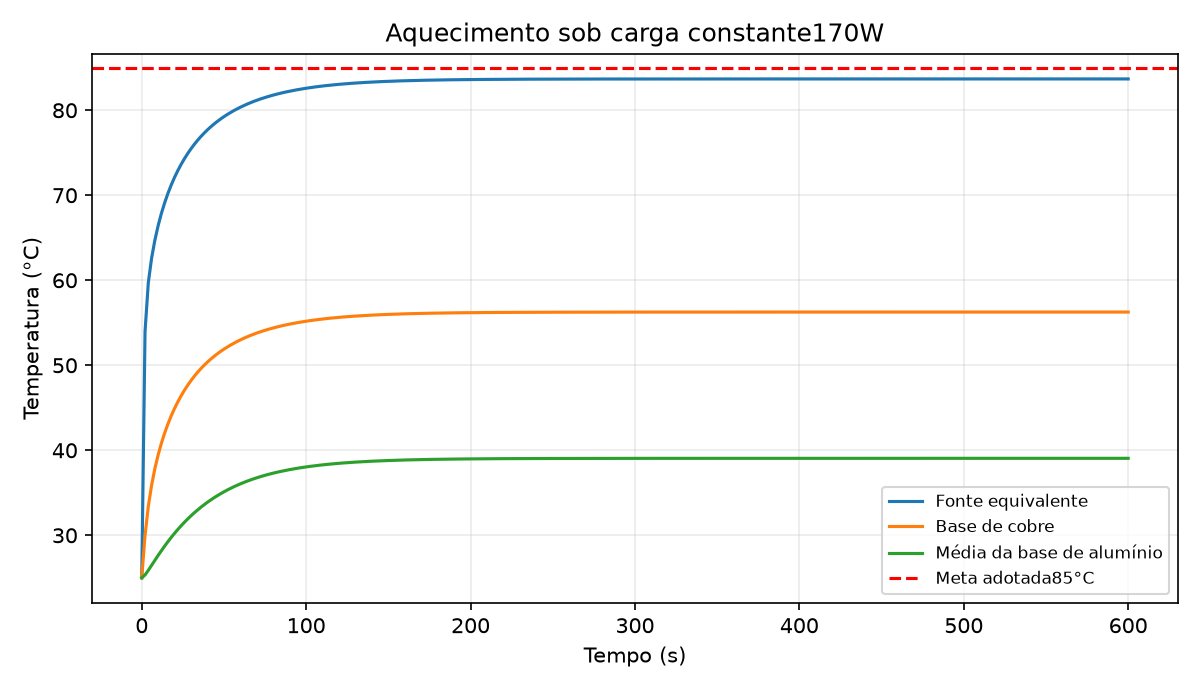

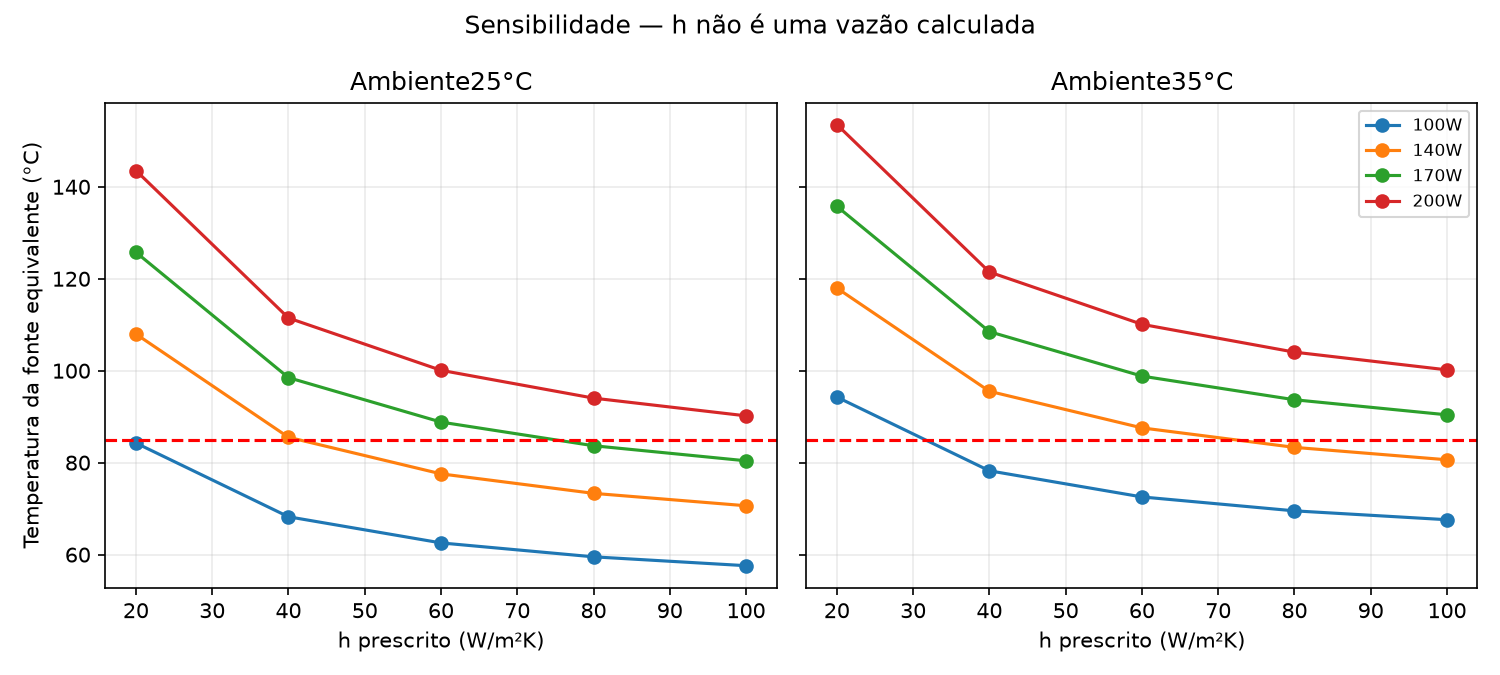

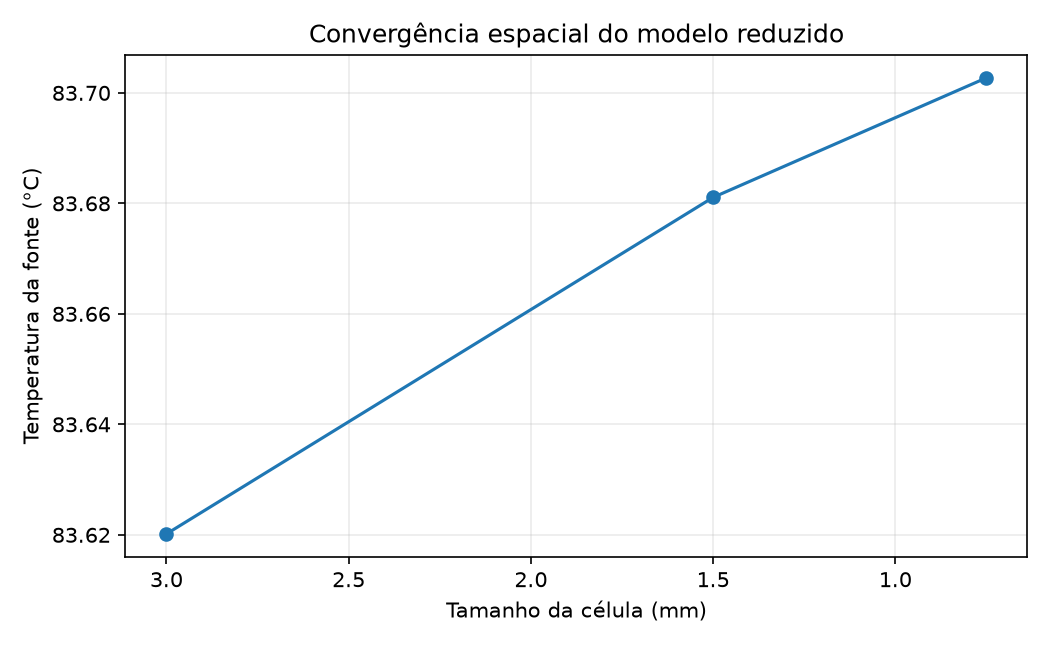

In [5]:
from IPython.display import display, Image
for name in ['temperature_map.png','transient.png','sensitivity.png','grid_convergence.png']:
    display(Image(filename=str(output_root/'figures'/name)))

## 6. Exportação
Os resultados são gravados em gpu_thermal_outputs/results. JSON de reprodução para o visualizador existente, CSV de cenários e transiente e resumo com unidades. A geometria didática deste estudo difere da GPU visual atual; importar as médias **não valida** aquela geometria nem habilita trocas físicas de peças.

In [6]:
import shutil
archive_path = shutil.make_archive(str(output_root), 'zip', output_root)
print('Arquivo de resultados:', archive_path)
try:
    from google.colab import files
except ImportError:
    print('Execução local: arquivos disponíveis na pasta acima.')
else:
    files.download(archive_path)

Arquivo de resultados: /tmp/faculdade-notebook-execution/gpu_thermal_outputs.zip
Execução local: arquivos disponíveis na pasta acima.


## Fontes
- MSI: https://storage-asset.msi.com/datasheet/vga/global/GeForce-RTX-3060-VENTUS-2X-12G-OC.pdf
- Hydro6063: https://www.hydro.com/globalassets/01-products--services/extruded-profiles/americas/ena-resources/alloy-data-sheets/hydro_2026_data_sheet_6063-rev-062026.pdf
- CDA C11000: https://alloys.copper.org/alloy/C11000
- MIT, aletas: https://web.mit.edu/16.unified/www/FALL/thermodynamics/notes/node128.html
- CoolProp: https://coolprop.org/coolprop/HighLevelAPI.html

Consulta:18out.2026. Condutividade da pasta, h, parâmetros do encapsulamento e contatos são hipóteses identificadas, não dados dessas fichas.